# CALOR Y MAYORES EN MADRID

## Análisis exploratorio: temperatura de superficie y forma urbana

**Datos:** tabla de hexágonos H3 (resolución 9) con la temperatura de superficie de verano (Landsat, julio-agosto 2023-2026) y 16 variables de forma urbana.

**Objetivo:** conocer la variable objetivo y las predictoras, decidir cómo tratar los nulos y los casos atípicos, y detectar variables redundantes antes del modelo.

## 1. Carga y revisión general

- importamos las librerías

In [1]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../scrips")
from config import RUTA_CLEAN

- cargamos la tabla de hexágonos y nos quedamos con los urbanos

In [2]:
hexagonos_todos = gpd.read_file(RUTA_CLEAN + "hexagonos_h3.gpkg")
hexagonos = hexagonos_todos[hexagonos_todos["urbano"]].copy()
print(hexagonos_todos.shape, hexagonos.shape)
hexagonos.head()

(5567, 21) (2931, 21)


,h3,urbano,lst,lst_pixeles,ndvi,albedo,pct_edificado,pct_industrial,edificabilidad,plantas_media,...,pct_copa,altura_arboles,arboles_ha,elevacion,dist_parque_grande,pct_viario,pct_ferrocarril,dist_agua,pct_suelo_desnudo,geometry
1,89390ca21a7ffff,True,45.111107,122,0.238576,0.188891,20.94,2.75,0.710,3.39,...,4.41,7.70,37.0,653.3,44.6,16.57,0.00,1877.5,0.0,"POLYGON ((448417.09 4476997.706, 448266.57 447..."
2,89390cb7267ffff,True,40.347608,121,0.525859,0.221615,0.30,0.00,0.006,1.85,...,33.82,NaN,0.0,649.4,176.4,0.00,0.00,5421.9,0.0,"POLYGON ((446589.157 4484004.363, 446438.615 4..."
5,89390ca154bffff,True,47.739784,119,0.183344,0.213762,10.41,10.41,0.111,1.07,...,0.04,NaN,0.0,560.2,66.0,10.01,0.00,79.3,11.6,"POLYGON ((443692.207 4465602.25, 443541.591 44..."
6,89390cb0a17ffff,True,42.385377,120,0.256784,0.186140,27.33,5.44,0.811,2.97,...,9.65,6.68,24.6,720.8,267.7,9.63,10.36,5373.8,0.0,"POLYGON ((442071.699 4479991.137, 441921.074 4..."
7,89390cb58c7ffff,True,51.910843,120,0.130826,0.234530,0.00,0.00,0.000,NaN,...,0.00,NaN,0.0,569.9,2610.9,0.00,0.00,347.1,100.0,"POLYGON ((454856.039 4480085.002, 454705.633 4..."


**Observación:** de los 5.567 hexágonos, 2.931 son urbanos; el análisis se hace solo con ellos.

- definimos la variable objetivo y las predictoras

In [3]:
target = "lst"
features = ["ndvi", "albedo", "pct_edificado", "pct_industrial", "edificabilidad",
               "plantas_media", "anio_medio", "pct_copa", "altura_arboles", "arboles_ha",
               "elevacion", "dist_parque_grande", "pct_viario", "pct_ferrocarril", "dist_agua", "pct_suelo_desnudo"]
print("features:", len(features))

features: 16


**Observación:** se analizan 16 features junto a la variable objetivo (lst).

- revisamos tipos y nulos

In [4]:
hexagonos[[target] + features].info()

<class 'pandas.DataFrame'>
Index: 2931 entries, 1 to 5566
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   lst                 2931 non-null   float64
 1   ndvi                2931 non-null   float64
 2   albedo              2931 non-null   float64
 3   pct_edificado       2931 non-null   float64
 4   pct_industrial      2931 non-null   float64
 5   edificabilidad      2931 non-null   float64
 6   plantas_media       2414 non-null   float64
 7   anio_medio          2414 non-null   float64
 8   pct_copa            2931 non-null   float64
 9   altura_arboles      2082 non-null   float64
 10  arboles_ha          2931 non-null   float64
 11  elevacion           2931 non-null   float64
 12  dist_parque_grande  2931 non-null   float64
 13  pct_viario          2931 non-null   float64
 14  pct_ferrocarril     2931 non-null   float64
 15  dist_agua           2931 non-null   float64
 16  pct_suelo_desnudo   29

**Observación:** las 16 columnas son numéricas; solo tres tienen valores vacíos.

In [5]:
(hexagonos[[target] + features].isnull().sum() / len(hexagonos) * 100).round(2).sort_values(ascending=False)

altura_arboles        28.97
plantas_media         17.64
anio_medio            17.64
lst                    0.00
ndvi                   0.00
pct_industrial         0.00
pct_edificado          0.00
edificabilidad         0.00
albedo                 0.00
pct_copa               0.00
arboles_ha             0.00
elevacion              0.00
dist_parque_grande     0.00
pct_viario             0.00
pct_ferrocarril        0.00
dist_agua              0.00
pct_suelo_desnudo      0.00
dtype: float64

**Observación:** altura_arboles está vacía en el 29 % de los hexágonos (sin árboles municipales) y plantas_media y anio_medio en el 17,6 % (sin edificios: parques, instalaciones deportivas, nudos viarios)

- estadísticos descriptivos

In [6]:
hexagonos[[target] + features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
lst,2931.0,45.21,2.88,34.62,43.27,44.79,46.98,54.65
ndvi,2931.0,0.24,0.11,0.00,0.16,0.22,0.31,0.72
albedo,2931.0,0.20,0.03,0.10,0.18,0.20,0.22,0.40
pct_edificado,2931.0,16.75,16.31,0.00,1.67,13.88,24.64,99.52
pct_industrial,2931.0,1.61,5.53,0.00,0.00,0.00,0.38,69.08
edificabilidad,2931.0,0.67,0.78,0.00,0.02,0.41,1.03,4.06
plantas_media,2414.0,3.65,2.12,1.00,1.81,3.45,5.08,16.88
anio_medio,2414.0,1980.39,22.62,1784.00,1968.00,1980.00,1997.00,2026.00
pct_copa,2931.0,13.06,20.43,0.00,0.66,5.64,14.60,100.00
altura_arboles,2082.0,7.19,2.03,1.67,5.64,7.14,8.52,19.25


**Observación:** la temperatura urbana media es de 45,2 °C (de 34,6 a 54,7 °C), algo más baja que la de todos los hexágonos (46,4 °C): las zonas no urbanas excluidas eran las más calientes. El % industrial y el ferrocarril son 0 en la mayoría de hexágonos, y la distancia mediana a un parque grande es de 210 m.

## 2. Tratamiento de nulos

**Decisión:** los vacíos significan "sin árboles" o "sin edificios". `altura_arboles` y `plantas_media` se rellenan con 0 (no hay árboles ni edificios, así que su altura es 0) y `anio_medio` con la mediana, porque un año 0 no tiene sentido y la mediana es un valor neutro.

- rellenamos los nulos según la decisión

In [7]:
hexagonos["altura_arboles"] = hexagonos["altura_arboles"].fillna(0)
hexagonos["plantas_media"] = hexagonos["plantas_media"].fillna(0)

mediana_anio = hexagonos["anio_medio"].median()
hexagonos["anio_medio"] = hexagonos["anio_medio"].fillna(mediana_anio)

print("Mediana del año:", mediana_anio)
print("Nulos restantes:", hexagonos[features].isnull().sum().sum())

Mediana del año: 1980.0
Nulos restantes: 0


**Observación:** la mediana del año de construcción es 1980; ya no quedan nulos.

## 3. Variable objetivo: temperatura de superficie

- distribución de la temperatura

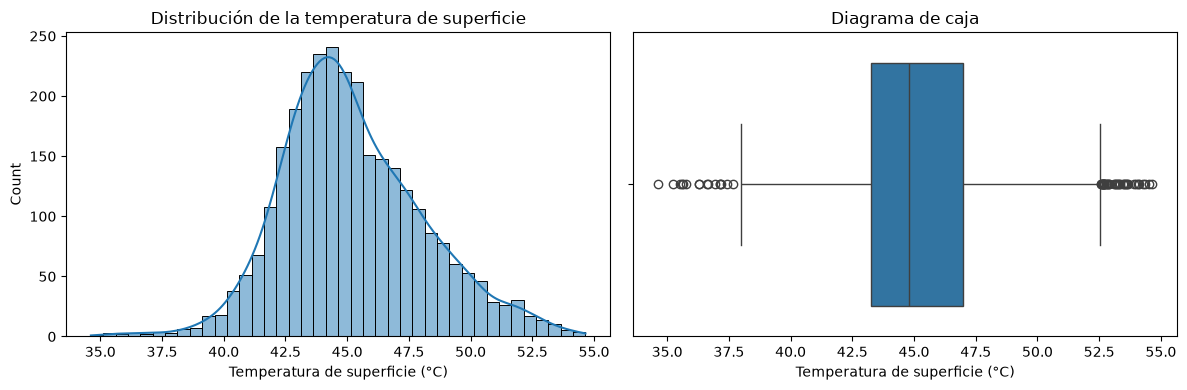

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(hexagonos[target], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribución de la temperatura de superficie")
axes[0].set_xlabel("Temperatura de superficie (°C)")
sns.boxplot(x=hexagonos[target], ax=axes[1])
axes[1].set_title("Diagrama de caja")
axes[1].set_xlabel("Temperatura de superficie (°C)")
plt.tight_layout()
plt.show()

**Observación:** la temperatura sigue una distribución casi normal, centrada en unos 44-45 °C, con una cola algo más larga hacia los valores calientes.

- contamos los valores atípicos con el criterio del rango intercuartílico

In [9]:
q1 = hexagonos[target].quantile(0.25)
q3 = hexagonos[target].quantile(0.75)
iqr = q3 - q1
for factor in [1.5, 2, 3]:
    limite_bajo = q1 - factor * iqr
    limite_alto = q3 + factor * iqr
    n_bajos = (hexagonos[target] < limite_bajo).sum()
    n_altos = (hexagonos[target] > limite_alto).sum()
    print(f"Factor {factor}: {n_bajos} por debajo de {limite_bajo:.1f} °C y {n_altos} por encima de {limite_alto:.1f} °C")

Factor 1.5: 16 por debajo de 37.7 °C y 38 por encima de 52.5 °C
Factor 2: 6 por debajo de 35.8 °C y 2 por encima de 54.4 °C
Factor 3: 0 por debajo de 32.1 °C y 0 por encima de 58.1 °C


**Observación:** con el criterio clásico (1,5 × IQR) hay 54 hexágonos atípicos (16 por debajo y 38 por encima, el 1,8 %); con el criterio estricto (3 × IQR) no hay ninguno, así que no son errores sino extremos reales.

- revisamos los 10 hexágonos más calientes y los 10 menos calientes

In [10]:
columnas_revision = ["h3", target, "ndvi", "pct_edificado", "pct_industrial", "pct_viario", "pct_ferrocarril", "pct_suelo_desnudo"]
hexagonos.nlargest(10, target)[columnas_revision]

,h3,lst,ndvi,pct_edificado,pct_industrial,pct_viario,pct_ferrocarril,pct_suelo_desnudo
1402,89390ca1eabffff,54.651711,0.197440,0.00,0.0,1.38,0.0,36.25
4099,89390ca1eb7ffff,54.501617,0.163813,0.00,0.0,0.63,0.0,89.04
3769,89390ca1ea3ffff,54.340656,0.160718,0.44,0.0,0.00,0.0,98.51
1514,89390cb5537ffff,54.281042,0.155870,0.00,0.0,0.00,0.0,100.00
3974,89390cb466fffff,54.097664,0.119266,0.00,0.0,0.00,0.0,100.00
1904,89390cb5567ffff,54.075195,0.162546,0.00,0.0,0.00,0.0,100.00
2756,89390cb42d3ffff,53.988813,0.141990,0.00,0.0,0.00,0.0,100.00
1157,89390cb5ec7ffff,53.912102,0.148597,0.00,0.0,0.00,0.0,100.00
5128,89390cb42cbffff,53.651078,0.094555,0.00,0.0,0.00,0.0,100.00
72,89390cb4667ffff,53.606974,0.128609,0.00,0.0,0.00,0.0,100.00


**Observación:** ninguno tiene edificios, industria ni apenas viario, y todos tienen muy poca vegetación (NDVI de 0,09 a 0,20): son suelo desnudo y seco (solares, terrenos sin uso, obras, pistas del aeropuerto).

In [11]:
hexagonos.nsmallest(10, target)[columnas_revision]

,h3,lst,ndvi,pct_edificado,pct_industrial,pct_viario,pct_ferrocarril,pct_suelo_desnudo
337,89390cb1857ffff,34.618230,0.720527,0.10,0.00,4.65,0.00,0.00
4267,89390ca264bffff,35.216065,0.580177,4.21,0.25,6.34,0.00,0.00
177,89390ca3597ffff,35.522225,0.668794,0.35,0.04,3.13,0.00,0.00
25,89390cb1a13ffff,35.586066,0.154386,0.73,0.00,0.00,0.00,61.14
1873,89390cb1a37ffff,35.631269,0.700268,2.46,0.00,1.35,0.00,0.00
4926,89390ca3587ffff,35.752011,0.699298,0.27,0.19,4.72,0.00,0.00
376,89390ca2643ffff,36.284785,0.656799,1.88,0.00,7.94,0.00,0.00
10,89390cb1843ffff,36.302400,0.595372,1.09,0.90,4.03,4.21,0.00
1251,89390ca3583ffff,36.621034,0.593405,3.33,0.04,7.81,0.00,0.00
1540,89390cb1853ffff,36.663660,0.605934,1.33,0.00,9.66,3.67,0.00


**Observación:** casi todos los hexágonos menos calientes son parques y zonas boscosas. La excepción es el Lago de la Casa de Campo, que el Urban Atlas 2021 clasifica como suelo sin uso (probablemente estaba vaciado en esa fecha) y no como agua.

- comprobamos la fila 25: calculamos las coordenadas de su centro para revisarla en Google Maps

In [12]:
hexagonos.loc[hexagonos["h3"] == "89390cb1a13ffff"].to_crs(epsg=4326).centroid

C:\Users\Usuario\AppData\Local\Temp\ipykernel_4112\3969871483.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  hexagonos.loc[hexagonos["h3"] == "89390cb1a13ffff"].to_crs(epsg=4326).centroid


25    POINT (-3.73295 40.41911)
dtype: geometry

**Decisión:** el hexágono del Lago de la Casa de Campo se mantiene sin corregir. El Urban Atlas 2021 lo clasifica como suelo sin uso, probablemente heredado de la capa de 2018, cuando el lago estaba vaciado (2017-2018): la versión 2021 se actualiza a partir de la de 2018 detectando solo cambios. La temperatura (2023-2026) corresponde al lago lleno. Se documenta como limitación por desfase temporal entre fuentes; afecta a un único hexágono.

## 4. Features

- distribución de cada feature

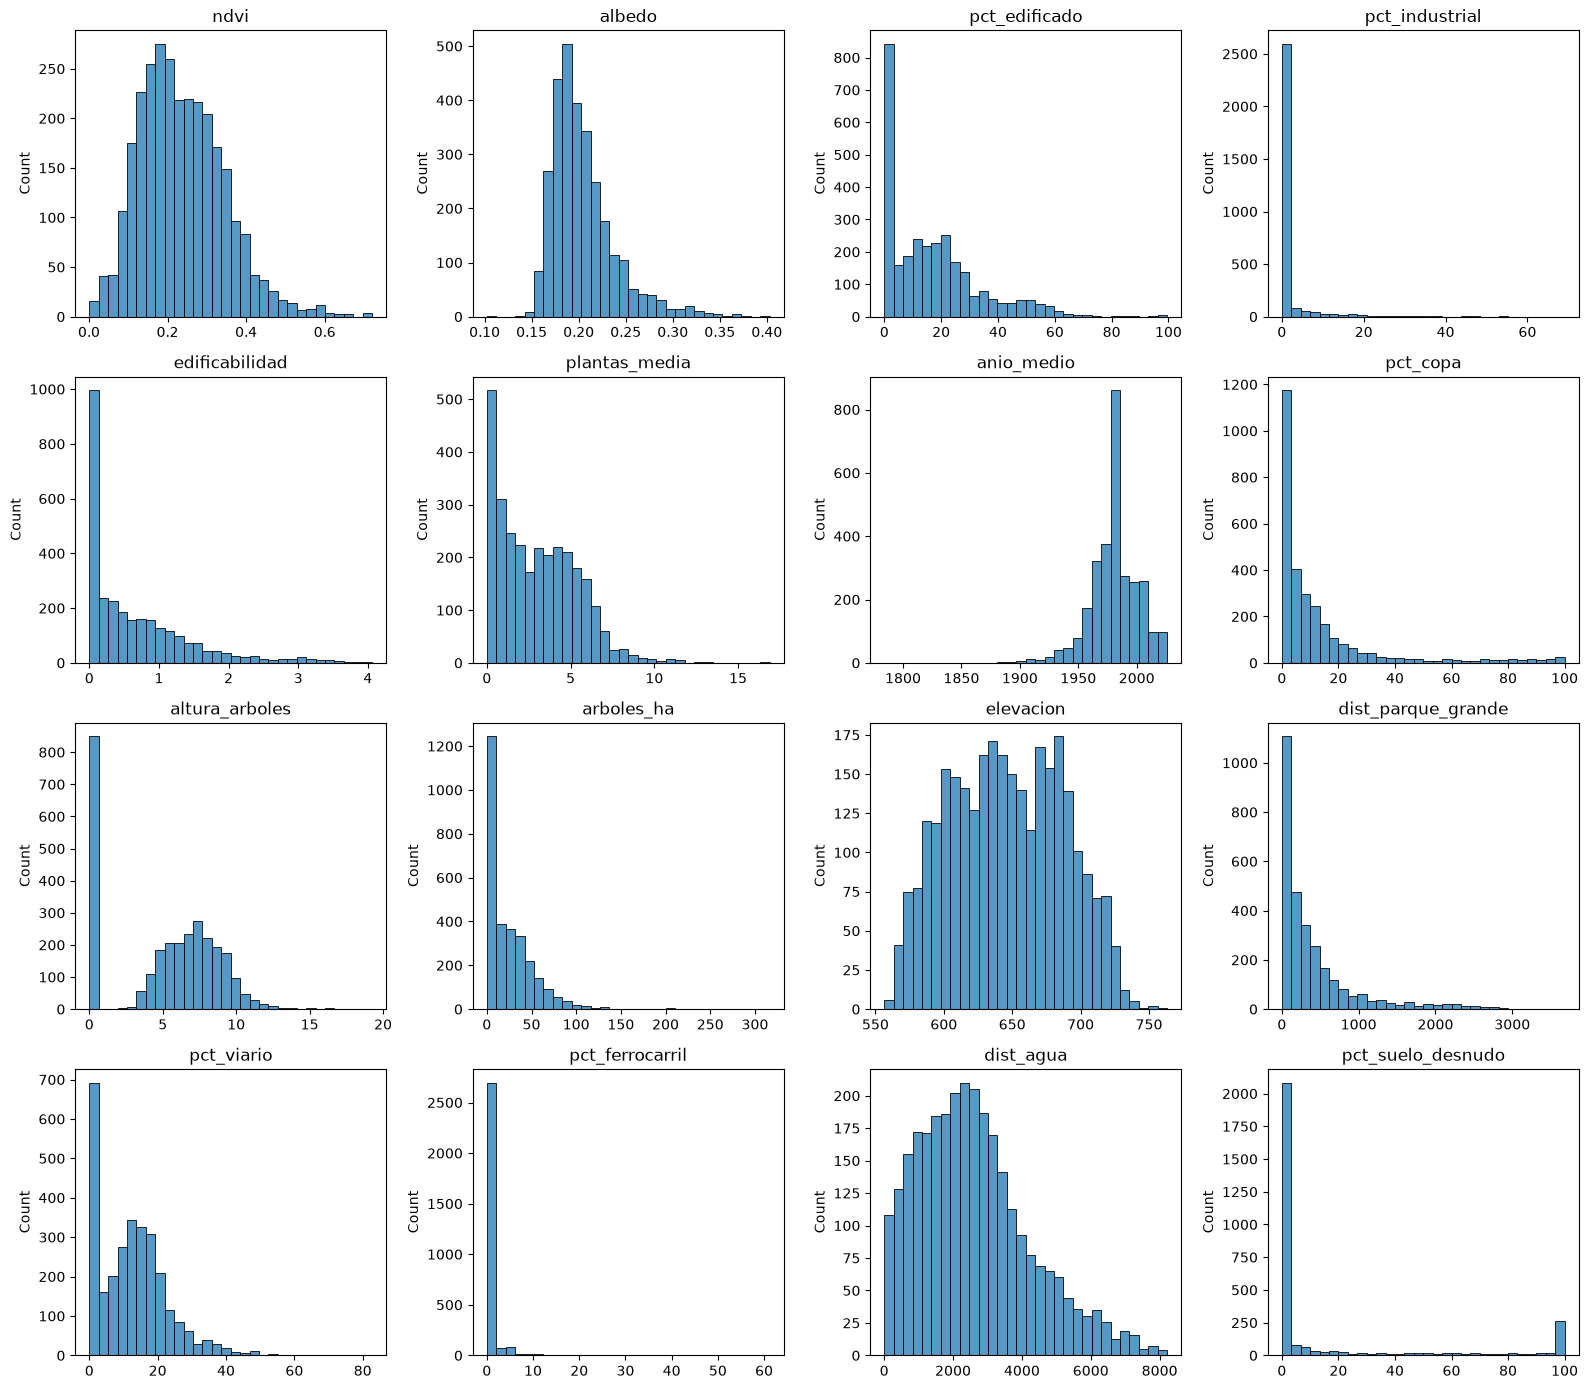

In [13]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for eje, columna in zip(axes.flatten(), features):
    sns.histplot(hexagonos[columna], bins=30, ax=eje)
    eje.set_title(columna)
    eje.set_xlabel("")
plt.tight_layout()
plt.show()

**Observación:** el NDVI, el albedo, la elevación y la distancia al agua tienen distribuciones continuas y sin extremos llamativos. En cambio, el % industrial, el ferrocarril, el suelo desnudo y la copa de árboles tienen una gran mayoría de ceros y unos pocos valores altos; el suelo desnudo es casi binario (0 o 100 %, con unos 250 hexágonos en el máximo). La edificabilidad, los árboles por hectárea y la distancia a parques grandes son muy asimétricas hacia la derecha. El pico de anio_medio en 1980 corresponde a los hexágonos sin edificios imputados con la mediana. Por estas formas, se espera que los modelos de árboles funcionen mejor que la regresión lineal.

- correlación de cada feature con el target

In [14]:
hexagonos[features + [target]].corr()[target].drop(target).sort_values()

ndvi                 -0.662741
altura_arboles       -0.527869
plantas_media        -0.488858
arboles_ha           -0.431103
pct_copa             -0.382350
edificabilidad       -0.338033
elevacion            -0.333616
pct_edificado        -0.277667
pct_viario           -0.218373
dist_agua            -0.034933
pct_ferrocarril       0.037244
pct_industrial        0.169896
anio_medio            0.233565
dist_parque_grande    0.470715
albedo                0.481580
pct_suelo_desnudo     0.628797
Name: lst, dtype: float64

**Observación:** el NDVI es la feature más relacionada con la temperatura (−0,66), seguida del suelo desnudo (+0,63), la altura de los árboles (−0,53) y las plantas de los edificios (−0,49). La distancia al agua y el ferrocarril apenas se relacionan de forma lineal (±0,04).

- matriz de correlación entre features, y el target, para detectar redundantes

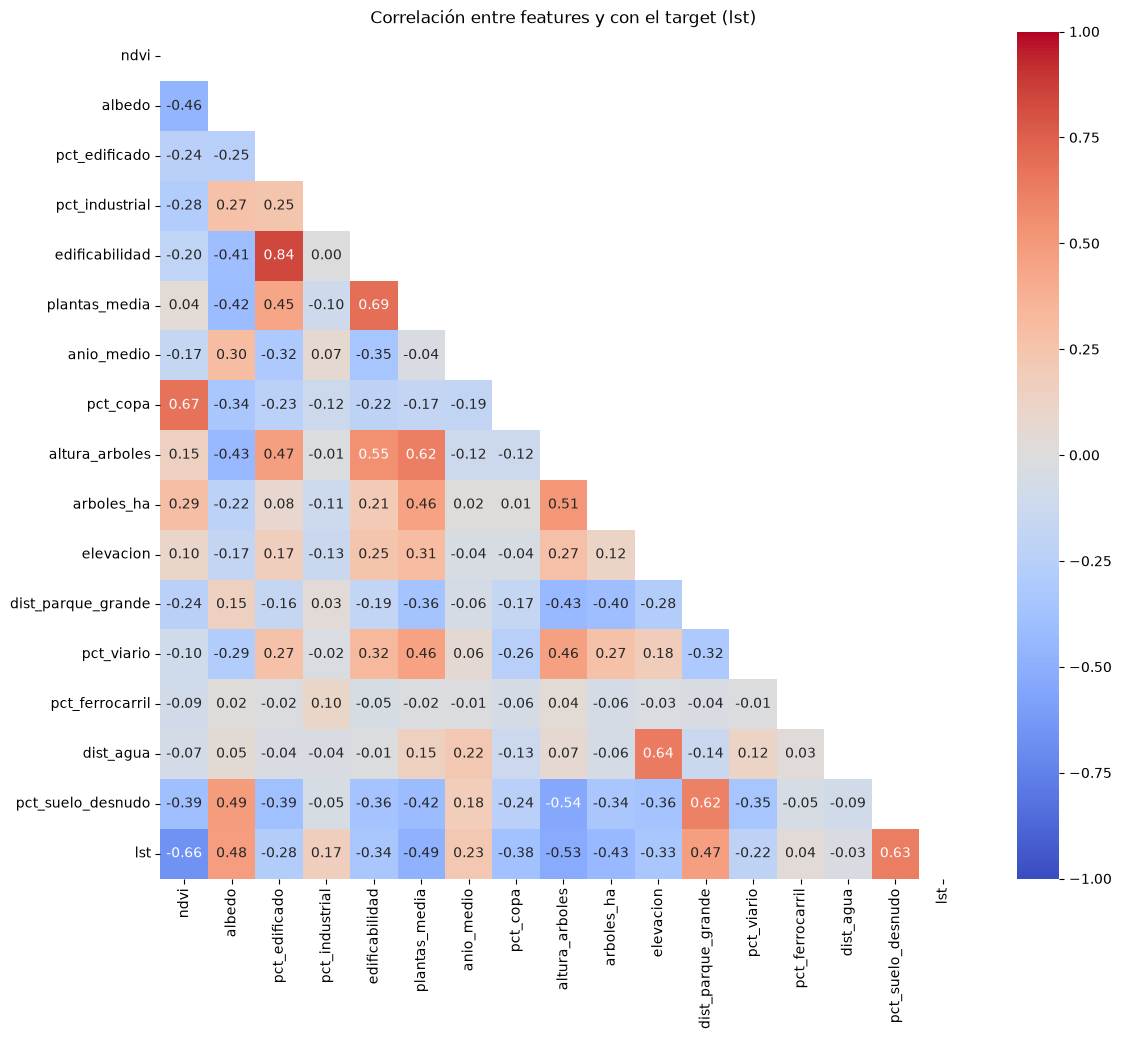

In [15]:
matriz = hexagonos[features + [target]].corr()
mascara_superior = np.triu(np.ones_like(matriz, dtype=bool))

plt.figure(figsize=(13, 11))
sns.heatmap(matriz, mask=mascara_superior, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre features y con el target (lst)")
plt.show()

**Observación:** solo un par supera 0,7: pct_edificado y edificabilidad (0,84). El resto de relaciones fuertes son moderadas, como NDVI y copa (0,67) o elevación y distancia al agua (0,64). Las que menos se relacionan con el target son pct_ferrocarril y dist_agua; se analizan a continuación antes de decidir.

In [16]:
hexagonos["tiene_ferrocarril"] = hexagonos["pct_ferrocarril"] > 0
hexagonos.groupby("tiene_ferrocarril")[target].agg(["count", "mean"]).round(2)

,count,mean
tiene_ferrocarril,,
False,2633,45.19
True,298,45.32


**Observación:** los hexágonos con vías de tren están de media a 45,3 °C y los que no tienen a 45,2 °C: apenas 0,1 °C de diferencia.

In [17]:
tramos_agua = pd.cut(hexagonos["dist_agua"], bins=[0, 250, 500, 1000, 2000, 10000])
hexagonos.groupby(tramos_agua)[target].agg(["count", "mean"]).round(2)

,count,mean
dist_agua,,
"(0, 250]",100,43.52
"(250, 500]",118,44.56
"(500, 1000]",277,45.29
"(1000, 2000]",664,45.68
"(2000, 10000]",1772,45.15


**Observación:** a menos de 250 m del agua la temperatura media es de 43,5 °C, entre 1,6 y 2,2 °C menos que a más de 500 m (45,2-45,7 °C). El efecto no es lineal: la temperatura sube hasta 1-2 km del agua y baja algo más lejos, por eso la correlación lineal es casi nula.

**Decisión:**
- Se elimina `edificabilidad` (correlación de 0,84 con `pct_edificado` y de 0,69 con `plantas_media`), porque equivale aproximadamente a su producto.
- Se elimina `pct_ferrocarril`, porque ni su correlación con la temperatura (0,04) ni la comparación entre hexágonos con y sin vías (0,1 °C de diferencia) muestran efecto.
- Se mantiene `dist_agua`: aunque su correlación es casi nula, a menos de 250 m del agua la temperatura es entre 1,6 y 2,2 °C menor; es un efecto local y no lineal que los modelos de árboles pueden aprender.

In [18]:
for feature in ["edificabilidad", "pct_ferrocarril"]:
    features.remove(feature)

hexagonos = hexagonos.drop(columns=["tiene_ferrocarril"])
print("Features:", len(features))

Features: 14


**Observación:** quedan 14 features para el modelo.

## 5. Relación de las features principales con el target

- gráficos de dispersión de las 6 features más relacionadas con la temperatura

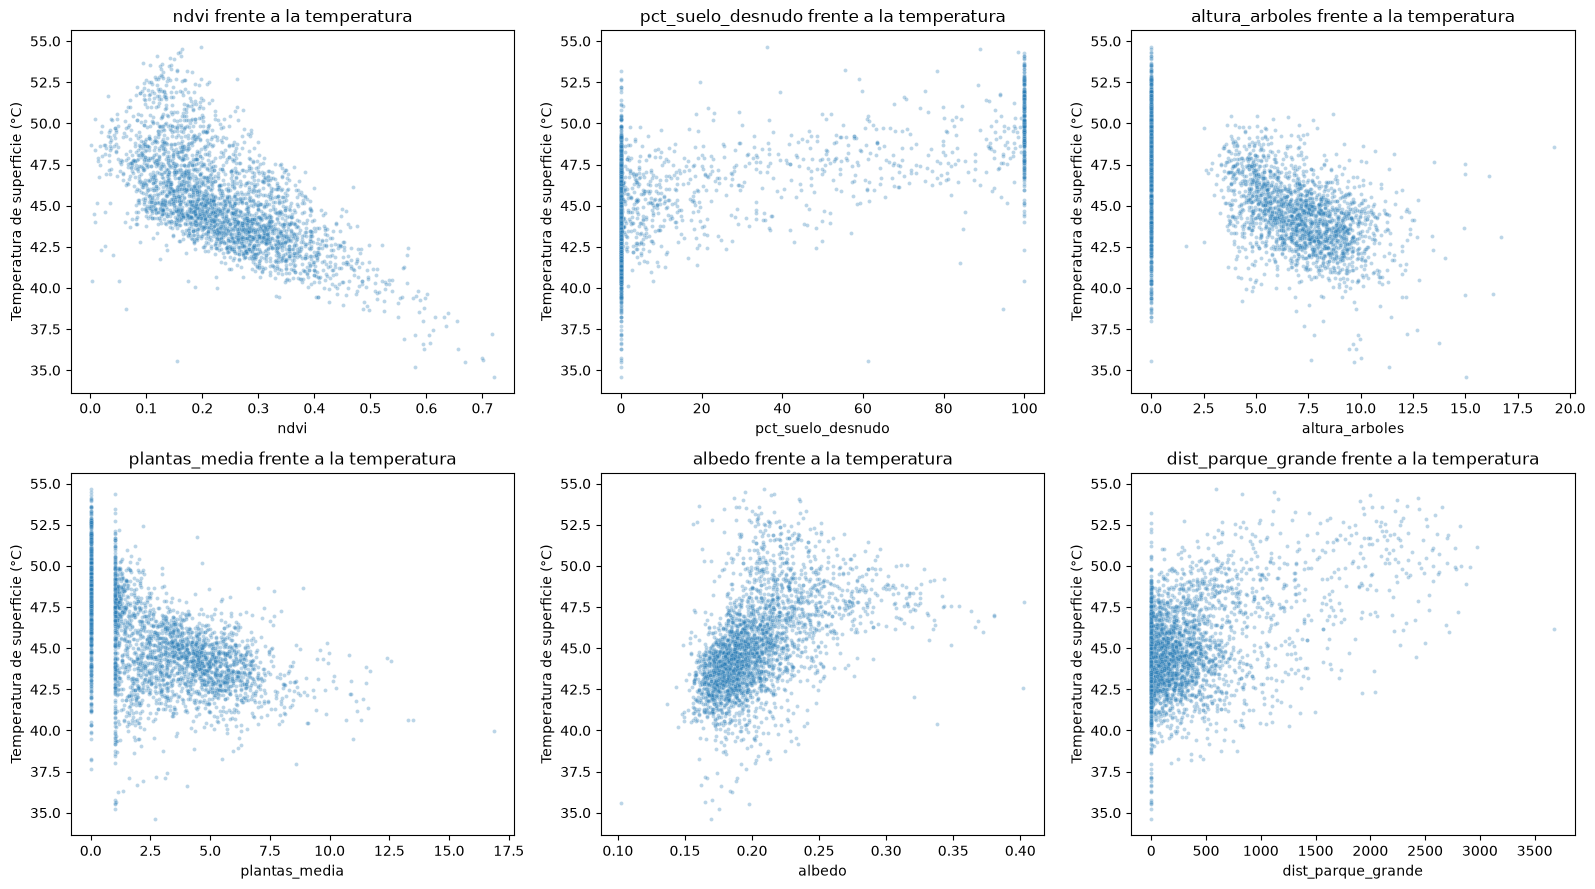

In [19]:
features_principales = ["ndvi", "pct_suelo_desnudo", "altura_arboles", "plantas_media", "albedo", "dist_parque_grande"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for eje, columna in zip(axes.flatten(), features_principales):
    sns.scatterplot(data=hexagonos, x=columna, y=target, s=8, alpha=0.3, ax=eje)
    eje.set_title(f"{columna} frente a la temperatura")
    eje.set_ylabel("Temperatura de superficie (°C)")
plt.tight_layout()
plt.show()

**Observación:** el NDVI muestra una relación lineal clara (más vegetación, menos calor). El suelo desnudo separa dos grupos: los hexágonos al 100 % están casi todos por encima de 47 °C. En altura de árboles y plantas, los hexágonos sin árboles o con 0-1 plantas abarcan todo el rango de temperatura, y a partir de ahí, más altura significa menos calor. Más allá de 1.500 m de un parque grande, casi todos los hexágonos superan los 45 °C.

## 6. Temperatura de los centros frente a la media urbana

- asignamos a cada centro la temperatura de su hexágono

In [20]:
centros = gpd.read_file(RUTA_CLEAN + "centros_mayores.gpkg")
centros_lst = gpd.sjoin(centros, hexagonos[["h3", target, "geometry"]], how="left", predicate="within")
print("Centros sin temperatura:", centros_lst[target].isnull().sum())
print("Temperatura media urbana:", round(hexagonos[target].mean(), 2))
print("Temperatura media del entorno de los centros:", round(centros_lst[target].mean(), 2))

Centros sin temperatura: 0
Temperatura media urbana: 45.21
Temperatura media del entorno de los centros: 43.97


**Observación:** el hexágono de los centros está de media a 44,0 °C, 1,2 °C menos que la media urbana (45,2 °C).

- comparamos por tipo de centro y por titularidad

In [21]:
centros_lst.groupby("tipo_centro")[target].agg(["count", "mean", "median"]).round(2)

,count,mean,median
tipo_centro,,,
centro de día,154,44.09,44.24
centro de mayores,112,44.10,44.38
residencia,165,43.80,43.78
vivienda tutelada,8,43.50,43.45


**Observación:** las diferencias entre tipos son pequeñas (de 43,5 a 44,1 °C de media); las residencias están algo menos calientes que los centros de día y los centros de mayores.

In [22]:
centros_lst.groupby("titularidad")[target].agg(["count", "mean", "median"]).round(2)

,count,mean,median
titularidad,,,
PRIVADA CON ÁNIMO DE LUCRO,182,43.88,43.94
PRIVADA SIN ÁNIMO DE LUCRO,51,43.81,43.98
PÚBLICA,206,44.10,44.34


**Observación:** los centros públicos están algo más calientes (44,1 °C) que los privados (43,8-43,9 °C), una diferencia pequeña, de unos 0,3 °C.

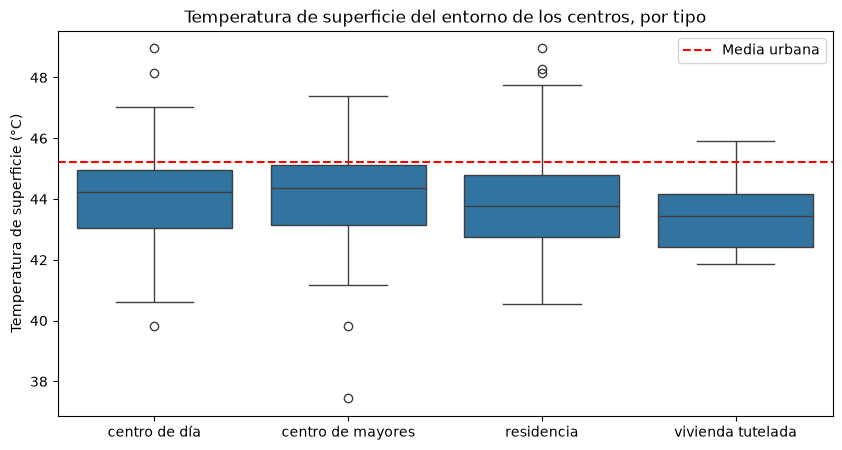

In [23]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=centros_lst, x="tipo_centro", y=target)
plt.axhline(hexagonos[target].mean(), color="red", linestyle="--", label="Media urbana")
plt.title("Temperatura de superficie del entorno de los centros, por tipo")
plt.ylabel("Temperatura de superficie (°C)")
plt.xlabel("")
plt.legend()
plt.show()

**Observación:** las medianas de todos los tipos quedan por debajo de la media urbana, pero cada grupo tiene centros por encima de 47-49 °C: son los candidatos prioritarios del índice de riesgo.

**Nota:** la media urbana incluye el aeropuerto, los polígonos y los solares, donde no vive nadie y que son lo más caliente. Por eso es lógico que los centros, situados en zonas residenciales, queden por debajo de esa media; aun así, cada tipo de centro tiene casos muy calientes.